# **Milestone 2**

Task 1

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
os.makedirs('/content/drive/MyDrive/nutriai_data', exist_ok=True)


Mounted at /content/drive


In [ ]:
!pip install kagglehub -q
import kagglehub
kagglehub.login()


Kaggle credentials set.
Kaggle credentials successfully validated.


In [ ]:
path = kagglehub.dataset_download("nudratabbas/vitamin-deficiency-disease-prediction-dataset")
print("Downloaded to:", path)

100%|██████████| 166k/166k [00:00<00:00, 53.5MB/s]

Extracting files...
Downloaded to: /root/.cache/kagglehub/datasets/nudratabbas/vitamin-deficiency-disease-prediction-dataset/versions/1


In [ ]:
import shutil, os

src = "/root/.cache/kagglehub/datasets/nudratabbas/vitamin-deficiency-disease-prediction-dataset/versions/1"
dst = "/content/drive/MyDrive/nutriai_data/kaggle"
os.makedirs(dst, exist_ok=True)

for filename in os.listdir(src):
    shutil.copy(os.path.join(src, filename), dst)

print("Copied files:", os.listdir(dst))


Copied files: ['vitamin_deficiency_disease_dataset_20260123.csv']


In [ ]:
import pandas as pd
kaggle_df = pd.read_csv('/content/drive/MyDrive/nutriai_data/kaggle/vitamin_deficiency_disease_dataset_20260123.csv')
print(kaggle_df.shape)
kaggle_df.head()


(4000, 34)


,age,gender,bmi,smoking_status,alcohol_consumption,exercise_level,diet_type,sun_exposure,income_level,latitude_region,...,has_night_blindness,has_fatigue,has_bleeding_gums,has_bone_pain,has_muscle_weakness,has_numbness_tingling,has_memory_problems,has_pale_skin,disease_diagnosis,has_multiple_deficiencies
0,79,Male,24.8,Former,NaN,Active,Vegetarian,High,High,Mid,...,0,0,0,0,0,0,0,0,Healthy,0
1,77,Female,39.9,Former,Moderate,Light,Omnivore,Low,Low,Low,...,0,0,0,1,0,0,0,0,Rickets_Osteomalacia,0
2,24,Male,26.4,Former,Heavy,Moderate,Omnivore,Low,High,High,...,1,0,0,0,0,0,0,0,Healthy,0
3,69,Male,23.1,Never,Heavy,Moderate,Vegetarian,High,Low,Low,...,0,0,0,0,0,1,1,0,Anemia,0
4,63,Male,29.6,Never,NaN,Moderate,Vegetarian,Moderate,High,Low,...,0,0,0,0,0,0,0,0,Healthy,0


In [ ]:
!pip install datasets -q
from datasets import load_dataset

hf_dataset = load_dataset("adarshzolekar/foods-nutrition-dataset")
print(hf_dataset)


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:121: UserWarning: 
Access to the secret `HF_TOKEN` has not been granted on this notebook.
You will not be requested again.
Please restart the session if you want to be prompted again.
  warnings.warn(


README.md:   0%|          | 0.00/1.93k [00:00<?, ?B/s]

foods.csv:   0%|          | 0.00/70.3k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1028 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['Food Items', 'Energy kcal', 'Carbs', 'Protein(g)', 'Fat(g)', 'Freesugar(g)', 'Fibre(g)', 'Cholestrol(mg)', 'Calcium(mg)'],
        num_rows: 1028
    })
})


In [ ]:
hf_dataset['train'].to_csv('/content/drive/MyDrive/nutriai_data/huggingface_food_nutrition.csv')
print("Saved to Drive!")


Creating CSV from Arrow format:   0%|          | 0/2 [00:00<?, ?ba/s]

Saved to Drive!


In [ ]:
hf_df = pd.read_csv('/content/drive/MyDrive/nutriai_data/huggingface_food_nutrition.csv')
print(hf_df.shape)
hf_df.head()



(1028, 9)


,Food Items,Energy kcal,Carbs,Protein(g),Fat(g),Freesugar(g),Fibre(g),Cholestrol(mg),Calcium(mg)
0,Butternaan,300.0,50.0,7.0,10.0,2.0,2.0,15.0,50.0
1,Cupcake,200.0,30.0,2.0,8.0,20.0,0.5,20.0,20.0
2,Donuts,250.0,30.0,3.0,12.0,10.0,1.0,20.0,20.0
3,French Fries,312.0,41.0,3.4,15.0,0.3,3.8,0.0,20.0
4,Garlic Bread,200.0,25.0,4.0,10.0,1.0,1.0,10.0,30.0


In [ ]:
import requests

headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"}

files_to_get = {
    "DEMO_J.XPT": "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/DEMO_J.XPT",
    "DR1TOT_J.XPT": "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/DR1TOT_J.XPT",
    "VID_J.XPT": "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/VID_J.XPT",
}

for filename, file_url in files_to_get.items():
    r = requests.get(file_url, headers=headers)
    path = f"/content/drive/MyDrive/nutriai_data/{filename}"
    with open(path, "wb") as f:
        f.write(r.content)
    print(filename, "- status:", r.status_code, "- size:", len(r.content), "bytes")


DEMO_J.XPT - status: 200 - size: 3412720 bytes
DR1TOT_J.XPT - status: 200 - size: 11722480 bytes
VID_J.XPT - status: 200 - size: 604400 bytes


In [ ]:
demo_df = pd.read_sas('/content/drive/MyDrive/nutriai_data/DEMO_J.XPT', format='xport')
diet_df = pd.read_sas('/content/drive/MyDrive/nutriai_data/DR1TOT_J.XPT', format='xport')
vid_df = pd.read_sas('/content/drive/MyDrive/nutriai_data/VID_J.XPT', format='xport')

print("Demographics:", demo_df.shape)
print("Dietary:", diet_df.shape)
print("Vitamin D:", vid_df.shape)

Demographics: (9254, 46)
Dietary: (8704, 168)
Vitamin D: (8366, 9)


In [ ]:
demo_df.head()


,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,RIDEXAGM,...,DMDHREDZ,DMDHRMAZ,DMDHSEDZ,WTINT2YR,WTMEC2YR,SDMVPSU,SDMVSTRA,INDHHIN2,INDFMIN2,INDFMPIR
0,93703.0,10.0,2.0,2.0,2.0,NaN,5.0,6.0,2.0,27.0,...,3.0,1.0,3.0,9246.491865,8539.731348,2.0,145.0,15.0,15.0,5.00
1,93704.0,10.0,2.0,1.0,2.0,NaN,3.0,3.0,1.0,33.0,...,3.0,1.0,2.0,37338.768343,42566.614750,1.0,143.0,15.0,15.0,5.00
2,93705.0,10.0,2.0,2.0,66.0,NaN,4.0,4.0,2.0,NaN,...,1.0,2.0,NaN,8614.571172,8338.419786,2.0,145.0,3.0,3.0,0.82
3,93706.0,10.0,2.0,1.0,18.0,NaN,5.0,6.0,2.0,222.0,...,3.0,1.0,2.0,8548.632619,8723.439814,2.0,134.0,NaN,NaN,NaN
4,93707.0,10.0,2.0,1.0,13.0,NaN,5.0,7.0,2.0,158.0,...,2.0,1.0,3.0,6769.344567,7064.609730,1.0,138.0,10.0,10.0,1.88


In [ ]:
diet_df.head()


,SEQN,WTDRD1,WTDR2D,DR1DRSTZ,DR1EXMER,DRABF,DRDINT,DR1DBIH,DR1DAY,DR1LANG,...,DRD370QQ,DRD370R,DRD370RQ,DRD370S,DRD370SQ,DRD370T,DRD370TQ,DRD370U,DRD370UQ,DRD370V
0,93703.0,5.397605e-79,NaN,5.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,93704.0,8.171401e+04,8.244287e+04,1.0,49.0,2.0,2.0,7.0,2.0,1.0,...,NaN,2.0,NaN,2.0,NaN,2.0,NaN,2.0,NaN,2.0
2,93705.0,7.185561e+03,5.640391e+03,1.0,73.0,2.0,2.0,5.0,1.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,93706.0,6.463883e+03,5.397605e-79,1.0,86.0,2.0,1.0,NaN,6.0,1.0,...,NaN,2.0,NaN,2.0,NaN,2.0,NaN,2.0,NaN,2.0
4,93707.0,1.533378e+04,2.270707e+04,1.0,81.0,2.0,2.0,14.0,2.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
vid_df.head()

,SEQN,LBXVIDMS,LBDVIDLC,LBXVD2MS,LBDVD2LC,LBXVD3MS,LBDVD3LC,LBXVE3MS,LBDVE3LC
0,93703.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,93704.0,74.4,5.397605e-79,1.45,1.0,73.0,5.397605e-79,5.84,5.397605e-79
2,93705.0,89.9,5.397605e-79,1.45,1.0,88.5,5.397605e-79,6.16,5.397605e-79
3,93706.0,53.8,5.397605e-79,1.45,1.0,52.4,5.397605e-79,2.70,5.397605e-79
4,93707.0,58.2,5.397605e-79,1.45,1.0,56.8,5.397605e-79,2.93,5.397605e-79


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Task - 2

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
os.makedirs('/content/drive/MyDrive/nutriai_data/nhanes_5datasets', exist_ok=True)

Mounted at /content/drive


In [ ]:
import requests

headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"}
base_url = "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/"

files_to_get = ["DEMO_L.XPT", "DR1TOT_L.XPT", "CBC_L.XPT", "VID_L.XPT", "FERTIN_L.XPT"]

for filename in files_to_get:
    r = requests.get(base_url + filename, headers=headers)
    path = f"/content/drive/MyDrive/nutriai_data/nhanes_5datasets/{filename}"
    with open(path, "wb") as f:
        f.write(r.content)
    print(filename, "- status:", r.status_code, "- size:", len(r.content), "bytes")

DEMO_L.XPT - status: 200 - size: 2582160 bytes
DR1TOT_L.XPT - status: 200 - size: 11932080 bytes
CBC_L.XPT - status: 200 - size: 1609840 bytes
VID_L.XPT - status: 200 - size: 700320 bytes
FERTIN_L.XPT - status: 200 - size: 83360 bytes


In [ ]:
import pandas as pd

folder = '/content/drive/MyDrive/nutriai_data/nhanes_5datasets'

demo_df   = pd.read_sas(f'{folder}/DEMO_L.XPT', format='xport')
diet_df   = pd.read_sas(f'{folder}/DR1TOT_L.XPT', format='xport')
cbc_df    = pd.read_sas(f'{folder}/CBC_L.XPT', format='xport')
vid_df    = pd.read_sas(f'{folder}/VID_L.XPT', format='xport')
fertin_df = pd.read_sas(f'{folder}/FERTIN_L.XPT', format='xport')

print("Demographics:", demo_df.shape)
print("Dietary (Day 1):", diet_df.shape)
print("CBC (Hemoglobin):", cbc_df.shape)
print("Vitamin D:", vid_df.shape)
print("Ferritin:", fertin_df.shape)

Demographics: (11933, 27)
Dietary (Day 1): (8860, 168)
CBC (Hemoglobin): (8727, 23)
Vitamin D: (8727, 10)
Ferritin: (2564, 4)


In [ ]:
demo_df.head()

,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,RIDEXAGM,...,DMDHRGND,DMDHRAGZ,DMDHREDZ,DMDHRMAZ,DMDHSEDZ,WTINT2YR,WTMEC2YR,SDMVSTRA,SDMVPSU,INDFMPIR
0,130378.0,12.0,2.0,1.0,43.0,NaN,5.0,6.0,2.0,NaN,...,NaN,NaN,NaN,NaN,NaN,50055.450807,54374.463898,173.0,2.0,5.00
1,130379.0,12.0,2.0,1.0,66.0,NaN,3.0,3.0,2.0,NaN,...,NaN,NaN,NaN,NaN,NaN,29087.450605,34084.721548,173.0,2.0,5.00
2,130380.0,12.0,2.0,2.0,44.0,NaN,2.0,2.0,1.0,NaN,...,NaN,NaN,NaN,NaN,NaN,80062.674301,81196.277992,174.0,1.0,1.41
3,130381.0,12.0,2.0,2.0,5.0,NaN,5.0,7.0,1.0,71.0,...,2.0,2.0,2.0,3.0,NaN,38807.268902,55698.607106,182.0,2.0,1.53
4,130382.0,12.0,2.0,1.0,2.0,NaN,3.0,3.0,2.0,34.0,...,2.0,2.0,3.0,1.0,2.0,30607.519774,36434.146346,182.0,2.0,3.60


In [ ]:
diet_df.head()

,SEQN,WTDRD1,WTDR2D,DR1DRSTZ,DR1EXMER,DRABF,DRDINT,DR1DBIH,DR1DAY,DR1LANG,...,DRD370QQ,DRD370R,DRD370RQ,DRD370S,DRD370SQ,DRD370T,DRD370TQ,DRD370U,DRD370UQ,DRD370V
0,130378.0,61366.555827,70554.222162,1.0,73.0,2.0,2.0,40.0,4.0,1.0,...,NaN,2.0,NaN,2.0,NaN,2.0,NaN,2.0,NaN,2.0
1,130379.0,34638.056480,36505.468348,1.0,73.0,2.0,2.0,19.0,4.0,1.0,...,1.0,2.0,NaN,2.0,NaN,2.0,NaN,2.0,NaN,2.0
2,130380.0,84728.261560,103979.190677,1.0,73.0,2.0,2.0,16.0,4.0,1.0,...,NaN,2.0,NaN,2.0,NaN,1.0,4.0,2.0,NaN,2.0
3,130381.0,61737.133446,75009.220819,1.0,91.0,2.0,2.0,23.0,5.0,1.0,...,NaN,2.0,NaN,2.0,NaN,2.0,NaN,2.0,NaN,2.0
4,130382.0,75846.746917,172361.851828,1.0,73.0,2.0,2.0,27.0,6.0,1.0,...,NaN,2.0,NaN,2.0,NaN,2.0,NaN,2.0,NaN,2.0


In [ ]:
cbc_df.head()

,SEQN,WTPH2YR,LBXWBCSI,LBXLYPCT,LBXMOPCT,LBXNEPCT,LBXEOPCT,LBXBAPCT,LBDLYMNO,LBDMONO,...,LBXRBCSI,LBXHGB,LBXHCT,LBXMCVSI,LBXMC,LBXMCHSI,LBXRDW,LBXPLTSI,LBXMPSI,LBXNRBC
0,130378.0,5.604213e+04,4.7,40.8,6.8,46.1,5.2,1.2,1.9,0.3,...,5.19,15.7,45.3,87.4,34.6,30.2,12.9,259.0,7.8,0.3
1,130379.0,3.743571e+04,6.3,25.4,14.2,57.3,2.5,0.7,1.6,0.9,...,4.59,15.2,43.9,95.8,34.5,33.0,12.8,221.0,8.5,0.1
2,130380.0,8.532884e+04,5.7,29.9,5.5,58.5,5.3,0.9,1.7,0.3,...,4.86,13.8,40.1,82.5,34.4,28.3,13.3,235.0,9.1,0.1
3,130381.0,5.397605e-79,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,130382.0,5.963893e+04,11.4,29.9,8.3,60.1,1.2,0.6,3.4,0.9,...,4.61,12.3,36.5,79.2,33.6,26.7,14.6,342.0,7.4,0.1


In [ ]:
vid_df.head()

,SEQN,WTPH2YR,LBXVIDMS,LBDVIDLC,LBXVD2MS,LBDVD2LC,LBXVD3MS,LBDVD3LC,LBXVE3MS,LBDVE3LC
0,130378.0,5.604213e+04,58.9,5.397605e-79,1.57,1.0,57.3,5.397605e-79,2.47,5.397605e-79
1,130379.0,3.743571e+04,60.5,5.397605e-79,1.57,1.0,58.9,5.397605e-79,3.40,5.397605e-79
2,130380.0,8.532884e+04,39.4,5.397605e-79,1.57,1.0,37.8,5.397605e-79,1.52,5.397605e-79
3,130381.0,5.397605e-79,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,130382.0,5.963893e+04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
fertin_df.head()

,SEQN,WTPH2YR,LBXFER,LBDFERSI
0,130380.0,8.532884e+04,13.3,13.3
1,130381.0,5.397605e-79,NaN,NaN
2,130382.0,5.963893e+04,24.4,24.4
3,130388.0,3.286429e+04,NaN,NaN
4,130390.0,6.142701e+04,52.1,52.1


Task 3

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

folder = '/content/drive/MyDrive/nutriai_data/nhanes_5datasets'

demo_df   = pd.read_sas(f'{folder}/DEMO_L.XPT', format='xport')
diet_df   = pd.read_sas(f'{folder}/DR1TOT_L.XPT', format='xport')
cbc_df    = pd.read_sas(f'{folder}/CBC_L.XPT', format='xport')
vid_df    = pd.read_sas(f'{folder}/VID_L.XPT', format='xport')
fertin_df = pd.read_sas(f'{folder}/FERTIN_L.XPT', format='xport')

print(demo_df.shape, diet_df.shape, cbc_df.shape, vid_df.shape, fertin_df.shape)

(11933, 27) (8860, 168) (8727, 23) (8727, 10) (2564, 4)


In [ ]:
DEMO_CDC_COLS = ["SEQN", "RIAGENDR", "RIDAGEYR"]
DIET_CDC_COLS = ["SEQN", "DR1TKCAL", "DR1TPROT", "DR1TIRON", "DR1TCALC",
                 "DR1TVD", "DR1TVB12", "DR1TFOLA", "DR1TVARA", "DR1TVC",
                 "DR1TMAGN", "DR1TZINC"]
CBC_CDC_COLS = ["SEQN", "LBXHGB"]
VID_CDC_COLS = ["SEQN", "LBXVIDMS"]
FER_CDC_COLS = ["SEQN", "LBXFER"]

NHANES_RENAME = {
    "SEQN": "person_id", "RIAGENDR": "gender", "RIDAGEYR": "age_years",
    "DR1TKCAL": "calories_kcal", "DR1TPROT": "protein_g", "DR1TIRON": "iron_mg",
    "DR1TCALC": "calcium_mg", "DR1TVD": "vitamin_d_mcg", "DR1TVB12": "vitamin_b12_mcg",
    "DR1TFOLA": "folate_mcg", "DR1TVARA": "vitamin_a_mcg", "DR1TVC": "vitamin_c_mg",
    "DR1TMAGN": "magnesium_mg", "DR1TZINC": "zinc_mg", "LBXHGB": "hemoglobin_g_dl",
    "LBXVIDMS": "serum_vitamin_d", "LBXFER": "ferritin",
}

In [ ]:
demo_clean   = demo_df[DEMO_CDC_COLS].rename(columns=NHANES_RENAME)
diet_clean   = diet_df[DIET_CDC_COLS].rename(columns=NHANES_RENAME)
cbc_clean    = cbc_df[CBC_CDC_COLS].rename(columns=NHANES_RENAME)
vid_clean    = vid_df[VID_CDC_COLS].rename(columns=NHANES_RENAME)
fertin_clean = fertin_df[FER_CDC_COLS].rename(columns=NHANES_RENAME)

In [ ]:
demo_filtered = demo_clean[(demo_clean["age_years"] >= 18) & (demo_clean["age_years"] <= 65)]
print("After age filter:", demo_filtered.shape)

After age filter: (5746, 3)


In [ ]:
final_df = demo_filtered.merge(diet_clean, on="person_id", how="left") \
                         .merge(cbc_clean, on="person_id", how="left") \
                         .merge(vid_clean, on="person_id", how="left") \
                         .merge(fertin_clean, on="person_id", how="left")

In [ ]:
save_path = f"{folder}/nhanes_merged_18_65.parquet"
final_df.to_parquet(save_path, index=False)
print("Saved:", save_path)

Saved: /content/drive/MyDrive/nutriai_data/nhanes_5datasets/nhanes_merged_18_65.parquet


In [ ]:
print("Final dataset shape:", final_df.shape)
print("\nColumn names:", list(final_df.columns))
print("\nFirst 5 rows:")
final_df.head()

Final dataset shape: (5746, 17)

Column names: ['person_id', 'gender', 'age_years', 'calories_kcal', 'protein_g', 'iron_mg', 'calcium_mg', 'vitamin_d_mcg', 'vitamin_b12_mcg', 'folate_mcg', 'vitamin_a_mcg', 'vitamin_c_mg', 'magnesium_mg', 'zinc_mg', 'hemoglobin_g_dl', 'serum_vitamin_d', 'ferritin']

First 5 rows:


,person_id,gender,age_years,calories_kcal,protein_g,iron_mg,calcium_mg,vitamin_d_mcg,vitamin_b12_mcg,folate_mcg,vitamin_a_mcg,vitamin_c_mg,magnesium_mg,zinc_mg,hemoglobin_g_dl,serum_vitamin_d,ferritin
0,130378.0,1.0,43.0,1740.0,80.46,9.86,693.0,0.2,1.79,403.0,771.0,22.0,204.0,8.78,15.7,58.9,NaN
1,130380.0,2.0,44.0,1995.0,69.86,10.46,1559.0,5.4,2.43,159.0,599.0,197.3,391.0,12.06,13.8,39.4,13.3
2,130384.0,1.0,43.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,130385.0,2.0,65.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,130386.0,1.0,34.0,2422.0,132.41,15.62,900.0,1.6,2.79,541.0,866.0,20.2,292.0,12.08,15.4,96.9,NaN


Task 4

In [ ]:
COLUMNS_NEEDED = [
    "gender", "age_years",
    "calories_kcal", "protein_g", "iron_mg", "calcium_mg", "vitamin_d_mcg",
    "vitamin_b12_mcg", "folate_mcg", "vitamin_a_mcg", "vitamin_c_mg",
    "magnesium_mg", "zinc_mg",
]

# Check all required columns actually exist
missing_cols = [c for c in COLUMNS_NEEDED if c not in final_df.columns]
print("Missing columns (should be empty):", missing_cols)

# Drop any row missing a value in these columns
df = final_df.dropna(subset=COLUMNS_NEEDED).copy()
print("Shape before:", final_df.shape, "→ Shape after dropna:", df.shape)

Missing columns (should be empty): []
Shape before: (5746, 17) → Shape after dropna: (3416, 17)


In [ ]:
import numpy as np

# --- Iron: uses lab values (hemoglobin/ferritin) when available, else falls back to intake ---
hgb = df["hemoglobin_g_dl"]
fer = df["ferritin"]
gender = df["gender"]

low_hgb = ((gender == 1) & (hgb < 13)) | ((gender == 2) & (hgb < 12))   # 1=male, 2=female
low_ferritin = fer < 30
lab_available_iron = hgb.notna() | fer.notna()

lab_deficient_iron = low_hgb.fillna(False) | low_ferritin.fillna(False)
intake_deficient_iron = df["iron_mg"] < 8

df["label_iron"] = np.where(lab_available_iron, lab_deficient_iron, intake_deficient_iron).astype(int)

# --- Vitamin D: uses serum lab value when available, else falls back to intake ---
lab_available_vd = df["serum_vitamin_d"].notna()
lab_deficient_vd = df["serum_vitamin_d"] < 50
intake_deficient_vd = df["vitamin_d_mcg"] < 15

df["label_vitamin_d"] = np.where(lab_available_vd, lab_deficient_vd, intake_deficient_vd).astype(int)

# --- Remaining labels: simple intake-threshold rules ---
df["label_vitamin_b12"] = (df["vitamin_b12_mcg"] < 2.4).astype(int)
df["label_calcium"]     = (df["calcium_mg"] < 1000).astype(int)
df["label_folate"]      = (df["folate_mcg"] < 400).astype(int)
df["label_vitamin_a"]   = (df["vitamin_a_mcg"] < 700).astype(int)
df["label_vitamin_c"]   = (df["vitamin_c_mg"] < 75).astype(int)
df["label_magnesium"]   = (df["magnesium_mg"] < 320).astype(int)
df["label_zinc"]        = (df["zinc_mg"] < 8).astype(int)
df["label_protein"]     = (df["protein_g"] < 50).astype(int)

LABEL_COLS = [
    "label_iron", "label_vitamin_d", "label_vitamin_b12", "label_calcium",
    "label_folate", "label_vitamin_a", "label_vitamin_c", "label_magnesium",
    "label_zinc", "label_protein",
]

print("Labels added:", LABEL_COLS)

Labels added: ['label_iron', 'label_vitamin_d', 'label_vitamin_b12', 'label_calcium', 'label_folate', 'label_vitamin_a', 'label_vitamin_c', 'label_magnesium', 'label_zinc', 'label_protein']


In [ ]:
print("Final shape:", df.shape)
print("\nAll columns:", list(df.columns))
print("\nLabel distribution (fraction flagged deficient):")
print(df[LABEL_COLS].mean().round(3))

df.head()

Final shape: (3416, 27)

All columns: ['person_id', 'gender', 'age_years', 'calories_kcal', 'protein_g', 'iron_mg', 'calcium_mg', 'vitamin_d_mcg', 'vitamin_b12_mcg', 'folate_mcg', 'vitamin_a_mcg', 'vitamin_c_mg', 'magnesium_mg', 'zinc_mg', 'hemoglobin_g_dl', 'serum_vitamin_d', 'ferritin', 'label_iron', 'label_vitamin_d', 'label_vitamin_b12', 'label_calcium', 'label_folate', 'label_vitamin_a', 'label_vitamin_c', 'label_magnesium', 'label_zinc', 'label_protein']

Label distribution (fraction flagged deficient):
label_iron           0.169
label_vitamin_d      0.286
label_vitamin_b12    0.361
label_calcium        0.663
label_folate         0.697
label_vitamin_a      0.732
label_vitamin_c      0.633
label_magnesium      0.646
label_zinc           0.441
label_protein        0.258
dtype: float64


,person_id,gender,age_years,calories_kcal,protein_g,iron_mg,calcium_mg,vitamin_d_mcg,vitamin_b12_mcg,folate_mcg,...,label_iron,label_vitamin_d,label_vitamin_b12,label_calcium,label_folate,label_vitamin_a,label_vitamin_c,label_magnesium,label_zinc,label_protein
0,130378.0,1.0,43.0,1740.0,80.46,9.86,693.0,0.2,1.79,403.0,...,0,0,1,1,0,0,1,1,0,0
1,130380.0,2.0,44.0,1995.0,69.86,10.46,1559.0,5.4,2.43,159.0,...,1,1,0,0,1,1,0,0,0,0
4,130386.0,1.0,34.0,2422.0,132.41,15.62,900.0,1.6,2.79,541.0,...,0,0,0,1,0,0,1,1,0,0
6,130389.0,1.0,59.0,1991.0,89.50,11.45,922.0,7.0,6.16,333.0,...,0,1,0,1,1,1,1,1,0,0
7,130390.0,2.0,31.0,1643.0,48.73,10.02,607.0,0.9,2.99,215.0,...,0,0,0,1,1,1,1,1,1,1


In [ ]:
save_path = "/content/drive/MyDrive/nutriai_data/nhanes_5datasets/nhanes_merged_18_65.parquet"
df.to_parquet(save_path, index=False)
print("Saved:", save_path)

Saved: /content/drive/MyDrive/nutriai_data/nhanes_5datasets/nhanes_merged_18_65.parquet


In [ ]:
import pandas as pd

final_df = pd.read_parquet('/content/drive/MyDrive/nutriai_data/nhanes_5datasets/nhanes_merged_18_65.parquet')
print(final_df.shape)

(3416, 27)


# **Milestone 2**

Task 5

Define features (X) and labels (y)

In [ ]:
FEATURE_COLS = [
    "gender", "age_years", "calories_kcal", "protein_g", "iron_mg", "calcium_mg",
    "vitamin_d_mcg", "vitamin_b12_mcg", "folate_mcg", "vitamin_a_mcg",
    "vitamin_c_mg", "magnesium_mg", "zinc_mg"
]

LABEL_COLS = [
    "label_iron", "label_vitamin_d", "label_vitamin_b12", "label_calcium",
    "label_folate", "label_vitamin_a", "label_vitamin_c", "label_magnesium",
    "label_zinc", "label_protein",
]

X = df[FEATURE_COLS]
y = df[LABEL_COLS]

print("X shape:", X.shape, "| y shape:", y.shape)

X shape: (3416, 13) | y shape: (3416, 10)


80/20 train-test split

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (2732, 13) Test: (684, 13)


Reusable scoring function

In [ ]:
import time
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

def train_and_score(model, model_name, X_train, y_train, X_test, y_test):
    print(f"Training {model_name} ...")
    start = time.time()
    model.fit(X_train, y_train)
    elapsed = time.time() - start
    print(f"{model_name} done in {elapsed:.1f}s")

    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test.values.flatten(), y_pred.flatten())
    f1_macro = f1_score(y_test, y_pred, average="macro")
    f1_micro = f1_score(y_test, y_pred, average="micro")

    print("=" * 70)
    print(f"SCORES — {model_name}")
    print("=" * 70)
    print(f"Accuracy (overall): {acc:.4f} ({acc*100:.2f}%)")
    print(f"F1 macro:           {f1_macro:.4f}")
    print(f"F1 micro:           {f1_micro:.4f}")

    per_label_f1 = f1_score(y_test, y_pred, average=None)
    report = pd.DataFrame({"nutrient": LABEL_COLS, "f1": per_label_f1})
    print("Per-nutrient F1:")
    print(report)

    return model, report

Random Forest


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf_model, rf_report = train_and_score(rf_model, "Random Forest", X_train, y_train, X_test, y_test)

Training Random Forest ...
Random Forest done in 4.7s
SCORES — Random Forest
Accuracy (overall): 0.9534 (95.34%)
F1 macro:           0.8261
F1 micro:           0.9505
Per-nutrient F1:
            nutrient        f1
0         label_iron  0.092308
1    label_vitamin_d  0.185654
2  label_vitamin_b12  1.000000
3      label_calcium  0.997748
4       label_folate  1.000000
5    label_vitamin_a  0.999011
6    label_vitamin_c  1.000000
7    label_magnesium  1.000000
8         label_zinc  1.000000
9      label_protein  0.986072


XGBoost

In [ ]:
!pip install xgboost -q
from xgboost import XGBClassifier
from sklearn.multioutput import MultiOutputClassifier

xgb_base = XGBClassifier(n_estimators=200, random_state=42, eval_metric="logloss")
xgb_model = MultiOutputClassifier(xgb_base)
xgb_model, xgb_report = train_and_score(xgb_model, "XGBoost", X_train, y_train, X_test, y_test)

Training XGBoost ...
XGBoost done in 4.6s
SCORES — XGBoost
Accuracy (overall): 0.9522 (95.22%)
F1 macro:           0.8674
F1 micro:           0.9503
Per-nutrient F1:
            nutrient        f1
0         label_iron  0.320856
1    label_vitamin_d  0.367893
2  label_vitamin_b12  0.997996
3      label_calcium  0.995506
4       label_folate  0.996785
5    label_vitamin_a  0.998024
6    label_vitamin_c  1.000000
7    label_magnesium  1.000000
8         label_zinc  1.000000
9      label_protein  0.997245


LightGBM

In [ ]:
!pip install lightgbm -q
from lightgbm import LGBMClassifier

lgbm_base = LGBMClassifier(n_estimators=200, random_state=42, verbose=-1)
lgbm_model = MultiOutputClassifier(lgbm_base)
lgbm_model, lgbm_report = train_and_score(lgbm_model, "LightGBM", X_train, y_train, X_test, y_test)

Training LightGBM ...
LightGBM done in 1.0s
SCORES — LightGBM
Accuracy (overall): 0.9554 (95.54%)
F1 macro:           0.8681
F1 micro:           0.9534
Per-nutrient F1:
            nutrient        f1
0         label_iron  0.310345
1    label_vitamin_d  0.380623
2  label_vitamin_b12  1.000000
3      label_calcium  0.998873
4       label_folate  1.000000
5    label_vitamin_a  0.997038
6    label_vitamin_c  1.000000
7    label_magnesium  1.000000
8         label_zinc  1.000000
9      label_protein  0.994475


CatBoost

In [ ]:
!pip install catboost -q
from catboost import CatBoostClassifier

cat_base = CatBoostClassifier(iterations=200, random_state=42, verbose=0)
cat_model = MultiOutputClassifier(cat_base)
cat_model, cat_report = train_and_score(cat_model, "CatBoost", X_train, y_train, X_test, y_test)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.7 MB/s eta 0:00:00
Training CatBoost ...
CatBoost done in 5.6s
SCORES — CatBoost
Accuracy (overall): 0.9545 (95.45%)
F1 macro:           0.8492
F1 micro:           0.9521
Per-nutrient F1:
            nutrient        f1
0         label_iron  0.232258
1    label_vitamin_d  0.268775
2  label_vitamin_b12  1.000000
3      label_calcium  0.995506
4       label_folate  1.000000
5    label_vitamin_a  1.000000
6    label_vitamin_c  0.997732
7    label_magnesium  1.000000
8         label_zinc  1.000000
9      label_protein  0.997245


In [ ]:
for col in ["calories_kcal", "protein_g", "iron_mg", "calcium_mg", "vitamin_d_mcg",
            "vitamin_b12_mcg", "folate_mcg", "vitamin_a_mcg", "vitamin_c_mg",
            "magnesium_mg", "zinc_mg"]:
    tiny_count = (df[col].abs() < 1e-10).sum()
    print(f"{col:20s} → suspiciously tiny values: {tiny_count}")

calories_kcal        → suspiciously tiny values: 4
protein_g            → suspiciously tiny values: 4
iron_mg              → suspiciously tiny values: 4
calcium_mg           → suspiciously tiny values: 2
vitamin_d_mcg        → suspiciously tiny values: 109
vitamin_b12_mcg      → suspiciously tiny values: 17
folate_mcg           → suspiciously tiny values: 4
vitamin_a_mcg        → suspiciously tiny values: 11
vitamin_c_mg         → suspiciously tiny values: 32
magnesium_mg         → suspiciously tiny values: 2
zinc_mg              → suspiciously tiny values: 3


In [ ]:
# Find rows where ANY of the diet columns has this fake near-zero value
diet_intake_cols = [
    "calories_kcal", "protein_g", "iron_mg", "calcium_mg", "vitamin_d_mcg",
    "vitamin_b12_mcg", "folate_mcg", "vitamin_a_mcg", "vitamin_c_mg",
    "magnesium_mg", "zinc_mg"
]

# This creates a True/False mask: True if ANY column in that row has a tiny fake value
mask = (final_df[diet_intake_cols].abs() < 1e-10).any(axis=1)

problem_rows = final_df[mask]
print("Number of affected rows:", problem_rows.shape[0])
problem_rows[["person_id"] + diet_intake_cols].head(10)

Number of affected rows: 134


,person_id,calories_kcal,protein_g,iron_mg,calcium_mg,vitamin_d_mcg,vitamin_b12_mcg,folate_mcg,vitamin_a_mcg,vitamin_c_mg,magnesium_mg,zinc_mg
6,130398.0,1109.0,32.42,6.97,534.0,5.397605e-79,0.17,504.0,4.0,5.970000e+01,282.0,3.64
7,130400.0,1278.0,55.20,10.79,193.0,5.397605e-79,3.19,210.0,24.0,2.500000e+00,103.0,9.80
9,130418.0,1357.0,7.81,1.99,474.0,5.397605e-79,0.06,69.0,13.0,1.200000e+00,181.0,1.84
78,130701.0,1593.0,73.90,26.50,711.0,5.397605e-79,0.87,403.0,1162.0,1.130000e+02,438.0,8.58
139,130914.0,210.0,9.98,0.73,49.0,5.397605e-79,0.10,24.0,173.0,1.510000e+01,35.0,0.84
143,130922.0,900.0,34.01,6.06,383.0,5.397605e-79,2.73,109.0,200.0,5.570000e+01,163.0,7.94
231,131225.0,1079.0,23.96,5.36,439.0,5.397605e-79,0.67,190.0,110.0,1.340000e+01,122.0,3.36
325,131503.0,578.0,12.04,2.38,252.0,5.397605e-79,0.21,79.0,46.0,1.430000e+01,100.0,1.73
357,131594.0,1932.0,46.35,11.11,649.0,2.700000e+00,2.00,243.0,168.0,5.397605e-79,139.0,6.93
367,131619.0,259.0,5.60,2.47,81.0,5.397605e-79,0.03,63.0,42.0,7.050000e+01,76.0,1.13


In [8]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd

df = pd.read_parquet('/content/drive/MyDrive/nutriai_data/nhanes_5datasets/nhanes_merged_18_65.parquet')
print(df.shape)
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(3416, 27)


,person_id,gender,age_years,calories_kcal,protein_g,iron_mg,calcium_mg,vitamin_d_mcg,vitamin_b12_mcg,folate_mcg,...,label_iron,label_vitamin_d,label_vitamin_b12,label_calcium,label_folate,label_vitamin_a,label_vitamin_c,label_magnesium,label_zinc,label_protein
0,130378.0,1.0,43.0,1740.0,80.46,9.86,693.0,0.2,1.79,403.0,...,0,0,1,1,0,0,1,1,0,0
1,130380.0,2.0,44.0,1995.0,69.86,10.46,1559.0,5.4,2.43,159.0,...,1,1,0,0,1,1,0,0,0,0
2,130386.0,1.0,34.0,2422.0,132.41,15.62,900.0,1.6,2.79,541.0,...,0,0,0,1,0,0,1,1,0,0
3,130389.0,1.0,59.0,1991.0,89.50,11.45,922.0,7.0,6.16,333.0,...,0,1,0,1,1,1,1,1,0,0
4,130390.0,2.0,31.0,1643.0,48.73,10.02,607.0,0.9,2.99,215.0,...,0,0,0,1,1,1,1,1,1,1


Task 6

Features, labels, split

In [11]:
FEATURE_COLS = [
    "gender", "age_years", "calories_kcal", "protein_g", "iron_mg", "calcium_mg",
    "vitamin_d_mcg", "vitamin_b12_mcg", "folate_mcg", "vitamin_a_mcg",
    "vitamin_c_mg", "magnesium_mg", "zinc_mg"
]
LABEL_COLS = [
    "label_iron", "label_vitamin_d", "label_vitamin_b12", "label_calcium",
    "label_folate", "label_vitamin_a", "label_vitamin_c", "label_magnesium",
    "label_zinc", "label_protein",
]

X = df[FEATURE_COLS]
Y = df[LABEL_COLS]

from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.20, random_state=42)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (2732, 13) Test: (684, 13)


Reusable scoring function

In [12]:
import time, pandas as pd
from sklearn.metrics import accuracy_score, f1_score

def train_and_score(model, name, X_train, Y_train, X_test, Y_test):
    print(f"Training {name} ...")
    start = time.time()
    model.fit(X_train, Y_train)
    print(f"{name} done in {time.time()-start:.1f}s")

    pred = model.predict(X_test)
    acc = accuracy_score(Y_test.values.flatten(), pred.flatten())
    f1_macro = f1_score(Y_test, pred, average="macro")
    f1_micro = f1_score(Y_test, pred, average="micro")
    per_f1 = pd.DataFrame({"nutrient": LABEL_COLS, "f1": f1_score(Y_test, pred, average=None)})

    print(f"Accuracy: {acc:.4f} | F1 macro: {f1_macro:.4f} | F1 micro: {f1_micro:.4f}")
    print(per_f1)

    return {"model": model, "pred": pred, "accuracy": acc, "f1_macro": f1_macro, "f1_micro": f1_micro, "per_f1": per_f1}

Train all 4 models

In [13]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
!pip install lightgbm catboost -q
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.multioutput import MultiOutputClassifier

results = {}

results["Random Forest"] = train_and_score(
    RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    "Random Forest", X_train, Y_train, X_test, Y_test
)

results["XGBoost"] = train_and_score(
    MultiOutputClassifier(XGBClassifier(n_estimators=200, random_state=42, eval_metric="logloss")),
    "XGBoost", X_train, Y_train, X_test, Y_test
)

results["LightGBM"] = train_and_score(
    MultiOutputClassifier(LGBMClassifier(n_estimators=200, random_state=42, verbose=-1)),
    "LightGBM", X_train, Y_train, X_test, Y_test
)

results["CatBoost"] = train_and_score(
    MultiOutputClassifier(CatBoostClassifier(iterations=200, random_state=42, verbose=0)),
    "CatBoost", X_train, Y_train, X_test, Y_test
)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.2 MB/s eta 0:00:00
Training Random Forest ...
Random Forest done in 3.5s
Accuracy: 0.9534 | F1 macro: 0.8261 | F1 micro: 0.9505
            nutrient        f1
0         label_iron  0.092308
1    label_vitamin_d  0.185654
2  label_vitamin_b12  1.000000
3      label_calcium  0.997748
4       label_folate  1.000000
5    label_vitamin_a  0.999011
6    label_vitamin_c  1.000000
7    label_magnesium  1.000000
8         label_zinc  1.000000
9      label_protein  0.986072
Training XGBoost ...
XGBoost done in 1.6s
Accuracy: 0.9522 | F1 macro: 0.8674 | F1 micro: 0.9503
            nutrient        f1
0         label_iron  0.320856
1    label_vitamin_d  0.367893
2  label_vitamin_b12  0.997996
3      label_calcium  0.995506
4       label_folate  0.996785
5    label_vitamin_a  0.998024
6    label_vitamin_c  1.000000
7    label_magnesium  1.000000
8         label_zinc  1.000000
9      label_protein  0.997245
Training LightGBM ...
LightGBM don

Compare all 4, pick the best

In [14]:
summary = pd.DataFrame({
    "model": list(results.keys()),
    "accuracy": [r["accuracy"] for r in results.values()],
    "f1_macro": [r["f1_macro"] for r in results.values()],
    "f1_micro": [r["f1_micro"] for r in results.values()],
}).sort_values("f1_macro", ascending=False)

print(summary)

best_name = summary.iloc[0]["model"]
best = results[best_name]
print(f"\n>>> BEST MODEL = {best_name} (F1 macro = {best['f1_macro']:.4f}, accuracy = {best['accuracy']*100:.2f}%)")

           model  accuracy  f1_macro  f1_micro
2       LightGBM  0.955409  0.868135  0.953428
1        XGBoost  0.952193  0.867430  0.950281
3       CatBoost  0.954532  0.849152  0.952102
0  Random Forest  0.953363  0.826079  0.950535

>>> BEST MODEL = LightGBM (F1 macro = 0.8681, accuracy = 95.54%)


Statistics for the best model (per-nutrient F1 chart)

/tmp/ipykernel_2152/2591494530.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(best["per_f1"]["nutrient"], rotation=45, ha="right")


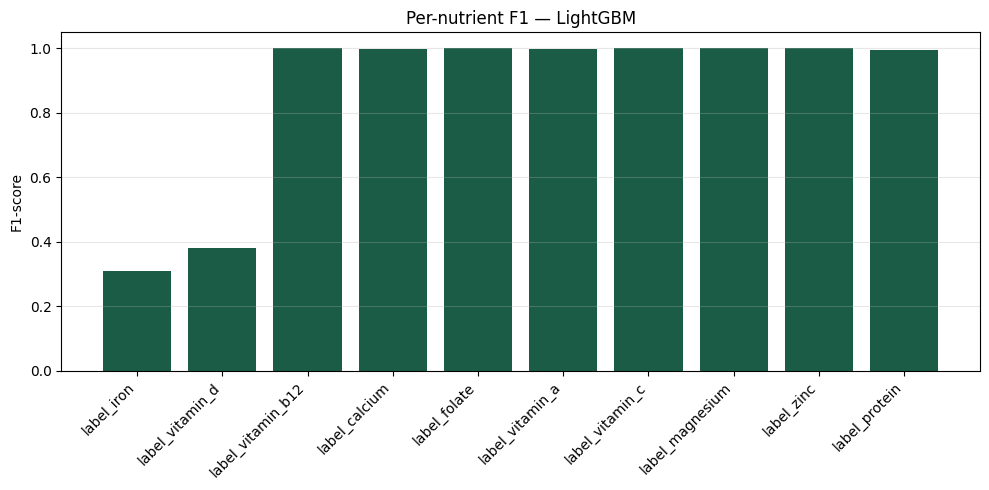

In [15]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(best["per_f1"]["nutrient"], best["per_f1"]["f1"], color="#1a5c45")
ax.set_xticklabels(best["per_f1"]["nutrient"], rotation=45, ha="right")
ax.set_ylabel("F1-score")
ax.set_ylim(0, 1.05)
ax.set_title(f"Per-nutrient F1 — {best_name}")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Confusion matrices for the best model (iron + vitamin D)

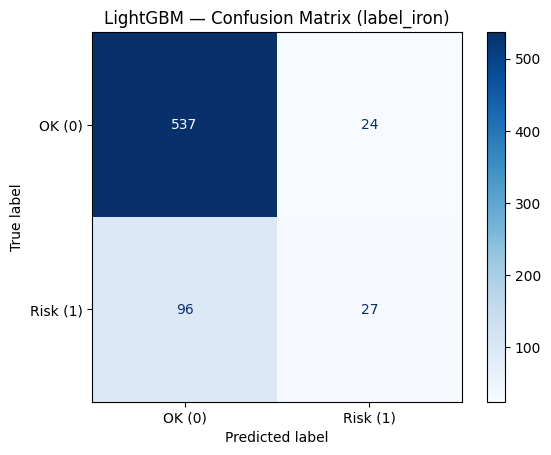

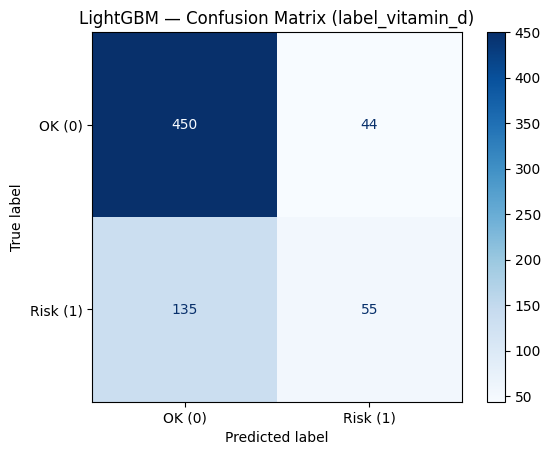

In [16]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

for label in ["label_iron", "label_vitamin_d"]:
    idx = LABEL_COLS.index(label)
    matrix = confusion_matrix(Y_test.iloc[:, idx], best["pred"][:, idx], labels=[0, 1])
    disp = ConfusionMatrixDisplay(confusion_matrix=matrix, display_labels=["OK (0)", "Risk (1)"])
    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"{best_name} — Confusion Matrix ({label})")
    plt.show()

ROC-AUC per nutrient for the best model

In [17]:
from sklearn.metrics import roc_auc_score

proba_list = best["model"].predict_proba(X_test)
roc_rows = []
for i, label in enumerate(LABEL_COLS):
    prob_positive = proba_list[i][:, 1]
    auc = roc_auc_score(Y_test.iloc[:, i], prob_positive)
    roc_rows.append({"nutrient": label, "roc_auc": auc})

roc_df = pd.DataFrame(roc_rows)
print(f"ROC-AUC per nutrient — {best_name}:")
print(roc_df)

ROC-AUC per nutrient — LightGBM:
            nutrient   roc_auc
0         label_iron  0.750533
1    label_vitamin_d  0.665843
2  label_vitamin_b12  1.000000
3      label_calcium  1.000000
4       label_folate  1.000000
5    label_vitamin_a  1.000000
6    label_vitamin_c  1.000000
7    label_magnesium  1.000000
8         label_zinc  1.000000
9      label_protein  1.000000


Save the best model

In [18]:
import joblib, json
from pathlib import Path

MODELS = Path("/content/drive/MyDrive/nutriai_data/nhanes_5datasets/models")
MODELS.mkdir(parents=True, exist_ok=True)

joblib.dump(best["model"], MODELS / "deficiency_model.joblib")

metrics_payload = {
    "best_model": best_name,
    "all_models": {name: {"accuracy": r["accuracy"], "f1_macro": r["f1_macro"], "f1_micro": r["f1_micro"]}
                   for name, r in results.items()},
    "per_nutrient_f1_best": best["per_f1"].to_dict(orient="records"),
    "roc_auc_per_nutrient": roc_df.to_dict(orient="records"),
}
with open(MODELS / "metrics.json", "w") as f:
    json.dump(metrics_payload, f, indent=2)

print("Saved model and metrics.json to Drive.")

Saved model and metrics.json to Drive.


In [19]:
# Smoke test — reload the saved model fresh and check it can predict
loaded_model = joblib.load(MODELS / "deficiency_model.joblib")

sample = X_test.iloc[:5]
predictions = loaded_model.predict(sample)

smoke = sample.copy()
for i, label in enumerate(LABEL_COLS):
    smoke[f"{label}_pred"] = predictions[:, i]

print("Smoke test — first 5 test rows with predictions:")
smoke

Smoke test — first 5 test rows with predictions:


,gender,age_years,calories_kcal,protein_g,iron_mg,calcium_mg,vitamin_d_mcg,vitamin_b12_mcg,folate_mcg,vitamin_a_mcg,...,label_iron_pred,label_vitamin_d_pred,label_vitamin_b12_pred,label_calcium_pred,label_folate_pred,label_vitamin_a_pred,label_vitamin_c_pred,label_magnesium_pred,label_zinc_pred,label_protein_pred
1963,2.0,46.0,525.0,28.66,2.17,367.0,0.3,2.19,120.0,214.0,...,0,0,1,1,1,1,1,1,1,1
1791,2.0,59.0,1977.0,80.32,12.79,792.0,4.8,4.51,245.0,214.0,...,0,0,0,1,1,1,1,1,0,0
170,2.0,23.0,577.0,31.37,4.04,525.0,0.3,1.52,180.0,205.0,...,1,0,1,1,1,1,1,1,1,1
680,1.0,60.0,2071.0,78.55,11.68,1469.0,3.9,3.01,305.0,658.0,...,0,0,0,0,1,1,1,1,0,0
3004,1.0,33.0,3788.0,116.26,13.42,960.0,2.6,6.41,233.0,398.0,...,0,0,0,1,1,1,1,1,0,0
